In [129]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


In [130]:
df = pd.read_csv('data/HRDataset_v14.csv')

# первые 5 строк
display(df.head())


,Employee_Name,EmpID,MarriedID,MaritalStatusID,GenderID,EmpStatusID,DeptID,PerfScoreID,FromDiversityJobFairID,Salary,Termd,PositionID,Position,State,Zip,DOB,Sex,MaritalDesc,CitizenDesc,HispanicLatino,RaceDesc,DateofHire,DateofTermination,TermReason,EmploymentStatus,Department,ManagerName,ManagerID,RecruitmentSource,PerformanceScore,EngagementSurvey,EmpSatisfaction,SpecialProjectsCount,LastPerformanceReview_Date,DaysLateLast30,Absences
0,"Adinolfi, Wilson K",10026,0,0,1,1,5,4,0,62506,0,19,Production Technician I,MA,1960,07/10/83,M,Single,US Citizen,No,White,7/5/2011,NaN,N/A-StillEmployed,Active,Production,Michael Albert,22.00,LinkedIn,Exceeds,4.60,5,0,1/17/2019,0,1
1,"Ait Sidi, Karthikeyan",10084,1,1,1,5,3,3,0,104437,1,27,Sr. DBA,MA,2148,05/05/75,M,Married,US Citizen,No,White,3/30/2015,6/16/2016,career change,Voluntarily Terminated,IT/IS,Simon Roup,4.00,Indeed,Fully Meets,4.96,3,6,2/24/2016,0,17
2,"Akinkuolie, Sarah",10196,1,1,0,5,5,3,0,64955,1,20,Production Technician II,MA,1810,09/19/88,F,Married,US Citizen,No,White,7/5/2011,9/24/2012,hours,Voluntarily Terminated,Production,Kissy Sullivan,20.00,LinkedIn,Fully Meets,3.02,3,0,5/15/2012,0,3
3,"Alagbe,Trina",10088,1,1,0,1,5,3,0,64991,0,19,Production Technician I,MA,1886,09/27/88,F,Married,US Citizen,No,White,1/7/2008,NaN,N/A-StillEmployed,Active,Production,Elijiah Gray,16.00,Indeed,Fully Meets,4.84,5,0,1/3/2019,0,15
4,"Anderson, Carol",10069,0,2,0,5,5,3,0,50825,1,19,Production Technician I,MA,2169,09/08/89,F,Divorced,US Citizen,No,White,7/11/2011,9/6/2016,return to school,Voluntarily Terminated,Production,Webster Butler,39.00,Google Search,Fully Meets,5.00,4,0,2/1/2016,0,2


In [131]:

# Размерность датасета
print(f"Количество наблюдений: {df.shape[0]}")
print(f"Количество признаков: {df.shape[1]}")

# информация о датасете
print("\nИнформация о датасете:")
df.info()

# типы данных
print("\nТипы данных:")
display(df.dtypes.to_frame(name='Тип данных'))

# статистические характеристики
print("\nОписательная статистика:")
display(df.describe(include='all').T)


Количество наблюдений: 311
Количество признаков: 36

Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 36 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Employee_Name               311 non-null    str    
 1   EmpID                       311 non-null    int64  
 2   MarriedID                   311 non-null    int64  
 3   MaritalStatusID             311 non-null    int64  
 4   GenderID                    311 non-null    int64  
 5   EmpStatusID                 311 non-null    int64  
 6   DeptID                      311 non-null    int64  
 7   PerfScoreID                 311 non-null    int64  
 8   FromDiversityJobFairID      311 non-null    int64  
 9   Salary                      311 non-null    int64  
 10  Termd                       311 non-null    int64  
 11  PositionID                  311 non-null    int64  
 12  Position                   

,Тип данных
Employee_Name,str
EmpID,int64
MarriedID,int64
MaritalStatusID,int64
GenderID,int64
EmpStatusID,int64
DeptID,int64
PerfScoreID,int64
FromDiversityJobFairID,int64
Salary,int64



Описательная статистика:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Employee_Name,311,311,"Adinolfi, Wilson K",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmpID,311.00,NaN,NaN,NaN,10156.00,89.92,10001.00,10078.50,10156.00,10233.50,10311.00
MarriedID,311.00,NaN,NaN,NaN,0.40,0.49,0.00,0.00,0.00,1.00,1.00
MaritalStatusID,311.00,NaN,NaN,NaN,0.81,0.94,0.00,0.00,1.00,1.00,4.00
GenderID,311.00,NaN,NaN,NaN,0.43,0.50,0.00,0.00,0.00,1.00,1.00
EmpStatusID,311.00,NaN,NaN,NaN,2.39,1.79,1.00,1.00,1.00,5.00,5.00
DeptID,311.00,NaN,NaN,NaN,4.61,1.08,1.00,5.00,5.00,5.00,6.00
PerfScoreID,311.00,NaN,NaN,NaN,2.98,0.59,1.00,3.00,3.00,3.00,4.00
FromDiversityJobFairID,311.00,NaN,NaN,NaN,0.09,0.29,0.00,0.00,0.00,0.00,1.00
Salary,311.00,NaN,NaN,NaN,69020.68,25156.64,45046.00,55501.50,62810.00,72036.00,250000.00


## Описание структуры и признаков датасета
Исходный набор данных содержит 311 наблюдений и 36 признаков. Каждая строка соответствует одному сотруднику компании
Признаки включают характеристики сотрудников, сведения о трудоустройстве, заработной плате, эффективности работы, удовлетворённости и вовлечённости

In [132]:

# Словарь признаков датасета

feature_descriptions = {
    'Employee_Name': 'Имя сотрудника',
    'EmpID': 'Уникальный идентификатор сотрудника',
    'MarriedID': 'Бинарный признак: состоит ли сотрудник в браке',
    'MaritalStatusID': 'Идентификатор семейного положения',
    'GenderID': 'Идентификатор пола сотрудника',
    'EmpStatusID': 'Идентификатор статуса занятости',
    'DeptID': 'Идентификатор подразделения',
    'PerfScoreID': 'Идентификатор оценки эффективности',
    'FromDiversityJobFairID': 'Признак найма через ярмарку вакансий',
    'Salary': 'Годовая заработная плата сотрудника',
    'Termd': 'Бинарный признак увольнения сотрудника',
    'PositionID': 'Идентификатор должности',
    'Position': 'Название должности',
    'State': 'Штат проживания сотрудника',
    'Zip': 'Почтовый индекс',
    'DOB': 'Дата рождения',
    'Sex': 'Пол сотрудника',
    'MaritalDesc': 'Семейное положение',
    'CitizenDesc': 'Гражданство',
    'HispanicLatino': 'Принадлежность к Hispanic/Latino',
    'RaceDesc': 'Расовая категория',
    'DateofHire': 'Дата приёма на работу',
    'DateofTermination': 'Дата увольнения',
    'TermReason': 'Причина увольнения или статус работающего сотрудника',
    'EmploymentStatus': 'Текущий статус занятости',
    'Department': 'Название подразделения',
    'ManagerName': 'Имя непосредственного руководителя',
    'ManagerID': 'Идентификатор руководителя',
    'RecruitmentSource': 'Источник привлечения сотрудника',
    'PerformanceScore': 'Текстовая оценка эффективности',
    'EngagementSurvey': 'Результат опроса вовлечённости',
    'EmpSatisfaction': 'Оценка удовлетворённости работой',
    'SpecialProjectsCount': 'Количество специальных проектов',
    'LastPerformanceReview_Date': 'Дата последней оценки эффективности',
    'DaysLateLast30': 'Количество дней опоздания за последние 30 дней',
    'Absences': 'Количество отсутствий'
}

# Формируем таблицу с описанием признаков
feature_info = pd.DataFrame({
    'Название признака': df.columns,
    'Описание': [feature_descriptions[col] for col in df.columns],
    'Тип данных': df.dtypes.astype(str).values
})

display(feature_info)


,Название признака,Описание,Тип данных
0,Employee_Name,Имя сотрудника,str
1,EmpID,Уникальный идентификатор сотрудника,int64
2,MarriedID,Бинарный признак: состоит ли сотрудник в браке,int64
3,MaritalStatusID,Идентификатор семейного положения,int64
4,GenderID,Идентификатор пола сотрудника,int64
5,EmpStatusID,Идентификатор статуса занятости,int64
6,DeptID,Идентификатор подразделения,int64
7,PerfScoreID,Идентификатор оценки эффективности,int64
8,FromDiversityJobFairID,Признак найма через ярмарку вакансий,int64
9,Salary,Годовая заработная плата сотрудника,int64


In [133]:

print(f"Количество строк: {len(df)}")
print(f"Количество столбцов: {len(df.columns)}")

print(f"\nОписано признаков: {len(feature_descriptions)}")
print(f"Неописанные признаки: {set(df.columns) - set(feature_descriptions.keys())}")

print(f"\nКоличество полных дубликатов: {df.duplicated().sum()}")
print(f"Количество уникальных сотрудников: {df['EmpID'].nunique()}")


Количество строк: 311
Количество столбцов: 36

Описано признаков: 36
Неописанные признаки: set()

Количество полных дубликатов: 0
Количество уникальных сотрудников: 311


## Фильтрация и сортировка данных
Выполняется фильтрация наблюдений по заданным условиям и сортировка полученных результатов

In [134]:

# Сотрудники с зарплатой выше 70 000
high_salary = df[df['Salary'] > 70000].sort_values(
    by='Salary',
    ascending=False
)

print(f"Количество сотрудников с зарплатой выше 70 000: {len(high_salary)}")

display(
    high_salary[['Employee_Name', 'Position', 'Department', 'Salary']].head(10)
)


Количество сотрудников с зарплатой выше 70 000: 89


,Employee_Name,Position,Department,Salary
150,"King, Janet",President & CEO,Executive Office,250000
308,"Zamora, Jennifer",CIO,IT/IS,220450
131,"Houlihan, Debra",Director of Sales,Sales,180000
96,"Foss, Jason",IT Director,IT/IS,178000
55,"Corleone, Vito",Director of Operations,Production,170500
190,"Monroe, Peter",IT Manager - Infra,IT/IS,157000
240,"Roper, Katie",Data Architect,IT/IS,150290
244,"Ruiz, Ricardo",IT Manager - DB,IT/IS,148999
243,"Roup,Simon",IT Manager - DB,IT/IS,140920
76,"Dougall, Eric",IT Manager - Support,IT/IS,138888


In [135]:

# Фильтрация по нескольким условиям
filtered_employees = df[
    (df['Department'] == 'Production') &
    (df['PerformanceScore'] == 'Fully Meets') &
    (df['Salary'] > 50000)
].sort_values(
    by='Salary',
    ascending=False
)

print(f"Количество сотрудников, соответствующих условиям: {len(filtered_employees)}")

display(
    filtered_employees[
        ['Employee_Name', 'Position', 'Salary', 'PerformanceScore']
    ].head(10)
)


Количество сотрудников, соответствующих условиям: 0


,Employee_Name,Position,Salary,PerformanceScore


In [136]:

# Рассчитываем медианную зарплату
salary_median = df['Salary'].median()

# Создаём бинарный признак с помощью lambda
df['HighSalary'] = df['Salary'].apply(
    lambda salary: 1 if salary >= salary_median else 0
)

print(f"Медианная зарплата: {salary_median:,.2f}")

display(
    df[['Employee_Name', 'Salary', 'HighSalary']].head(10)
)

print("\nРаспределение сотрудников:")
display(df['HighSalary'].value_counts().sort_index())


Медианная зарплата: 62,810.00


,Employee_Name,Salary,HighSalary
0,"Adinolfi, Wilson K",62506,0
1,"Ait Sidi, Karthikeyan",104437,1
2,"Akinkuolie, Sarah",64955,1
3,"Alagbe,Trina",64991,1
4,"Anderson, Carol",50825,0
5,"Anderson, Linda",57568,0
6,"Andreola, Colby",95660,1
7,"Athwal, Sam",59365,0
8,"Bachiochi, Linda",47837,0
9,"Bacong, Alejandro",50178,0



Распределение сотрудников:


HighSalary
0    155
1    156
Name: count, dtype: int64

In [137]:
print('Уникальные подразделения:')
display(df['Department'].value_counts(dropna=False))

print('\nУникальные оценки эффективности:')
display(df['PerformanceScore'].value_counts(dropna=False))

print('\nМинимальная и максимальная зарплата:')
print(df['Salary'].min(), '-', df['Salary'].max())

Уникальные подразделения:


Department
Production              209
IT/IS                    50
Sales                    31
Software Engineering     11
Admin Offices             9
Executive Office          1
Name: count, dtype: int64


Уникальные оценки эффективности:


PerformanceScore
Fully Meets          243
Exceeds               37
Needs Improvement     18
PIP                   13
Name: count, dtype: int64


Минимальная и максимальная зарплата:
45046 - 250000


In [138]:
# Преобразуем даты в формат datetime
df['DateofHire'] = pd.to_datetime(
    df['DateofHire'],
    errors='coerce'
)

df['DateofTermination'] = pd.to_datetime(
    df['DateofTermination'],
    errors='coerce'
)

df['LastPerformanceReview_Date'] = pd.to_datetime(
    df['LastPerformanceReview_Date'],
    errors='coerce'
)

# Используем максимальную дату последней оценки как условную дату среза
analysis_date = df['LastPerformanceReview_Date'].max()

print(f'Условная дата анализа: {analysis_date.date()}')

# Функция расчёта фактического стажа
def calculate_tenure(row):
    hire_date = row['DateofHire']
    termination_date = row['DateofTermination']

    if pd.isna(hire_date):
        return np.nan

    # Для уволенных — дата увольнения,
    # для работающих — условная дата анализа
    end_date = termination_date if pd.notna(termination_date) else analysis_date

    # Не допускаем расчёта стажа за пределами даты среза
    end_date = min(end_date, analysis_date)

    return round((end_date - hire_date).days / 365.25, 2)


# Пересчитываем стаж
df['TenureYears'] = df.apply(calculate_tenure, axis=1)

display(
    df[
        ['Employee_Name', 'DateofHire', 'DateofTermination', 'TenureYears']
    ].head(15)
)

Условная дата анализа: 2019-02-28


,Employee_Name,DateofHire,DateofTermination,TenureYears
0,"Adinolfi, Wilson K",2011-07-05,NaT,7.65
1,"Ait Sidi, Karthikeyan",2015-03-30,2016-06-16,1.22
2,"Akinkuolie, Sarah",2011-07-05,2012-09-24,1.22
3,"Alagbe,Trina",2008-01-07,NaT,11.14
4,"Anderson, Carol",2011-07-11,2016-09-06,5.16
5,"Anderson, Linda",2012-01-09,NaT,7.14
6,"Andreola, Colby",2014-11-10,NaT,4.30
7,"Athwal, Sam",2013-09-30,NaT,5.41
8,"Bachiochi, Linda",2009-07-06,NaT,9.65
9,"Bacong, Alejandro",2015-01-05,NaT,4.15


In [139]:
# Проверяем сочетания подразделений и оценок эффективности
display(
    pd.crosstab(
        df['Department'],
        df['PerformanceScore']
    )
)

# Проверяем, есть ли сотрудники Production с оценкой Fully Meets
check = df[
    (df['Department'].astype(str).str.strip() == 'Production') &
    (df['PerformanceScore'].astype(str).str.strip() == 'Fully Meets')
]

print(f"Количество сотрудников Production с оценкой Fully Meets: {len(check)}")

display(
    check[['Employee_Name', 'Department', 'PerformanceScore', 'Salary']].head(10)
)

PerformanceScore,Exceeds,Fully Meets,Needs Improvement,PIP
Department,,,,
Admin Offices,0,9,0,0
Executive Office,0,1,0,0
IT/IS,6,42,1,1
Production,27,159,15,8
Sales,2,24,1,4
Software Engineering,2,8,1,0


Количество сотрудников Production с оценкой Fully Meets: 159


,Employee_Name,Department,PerformanceScore,Salary
2,"Akinkuolie, Sarah",Production,Fully Meets,64955
3,"Alagbe,Trina",Production,Fully Meets,64991
4,"Anderson, Carol",Production,Fully Meets,50825
7,"Athwal, Sam",Production,Fully Meets,59365
8,"Bachiochi, Linda",Production,Fully Meets,47837
10,"Baczenski, Rachael",Production,Fully Meets,54670
11,"Barbara, Thomas",Production,Fully Meets,47211
13,"Barone, Francesco A",Production,Fully Meets,58709
14,"Barton, Nader",Production,Fully Meets,52505
15,"Bates, Norman",Production,Fully Meets,57834


In [140]:
filtered_employees = df[
    (df['Department'].astype(str).str.strip() == 'Production') &
    (df['PerformanceScore'].astype(str).str.strip() == 'Fully Meets') &
    (df['Salary'] > 50000)
].sort_values(
    by='Salary',
    ascending=False
)

print(f"Количество сотрудников, соответствующих условиям: {len(filtered_employees)}")

display(
    filtered_employees[
        ['Employee_Name', 'Position', 'Salary', 'PerformanceScore']
    ].head(10)
)

Количество сотрудников, соответствующих условиям: 136


,Employee_Name,Position,Salary,PerformanceScore
290,"Vega, Vincent",Production Manager,88976,Fully Meets
187,"Miller, Brannon",Production Manager,83667,Fully Meets
157,"Landa, Hans",Production Manager,82758,Fully Meets
296,"Wallace, Courtney E",Production Manager,80512,Fully Meets
78,"Dunn, Amy",Production Manager,75188,Fully Meets
286,"Trzeciak, Cybil",Production Technician II,74813,Fully Meets
218,"Peterson, Ebonee",Production Manager,74669,Fully Meets
195,"Moumanil, Maliki",Production Technician II,74417,Fully Meets
27,"Bozzi, Charles",Production Manager,74312,Fully Meets
219,"Petingill, Shana",Production Technician II,74226,Fully Meets


**Выводы по фильтрации и созданию признаков**

В результате: 89 сотрудников из 311 получают заработную плату выше 70 000. При одновременном учёте подразделения, оценки эффективности и уровня заработной платы условию соответствуют 136 сотрудников подразделения Production с оценкой Fully Meets и зарплатой выше 50 000.

На основе медианной заработной платы (62 810) создан бинарный признак HighSalary, разделяющий сотрудников на две группы: 155 человек имеют зарплату ниже медианы, 156 человек на уровне медианы или выше.

Дополнительно создан признак TenureYears, отражающий продолжительность работы сотрудника в компании. Для действующих сотрудников использована условная дата анализа 28.02.2019, для уволенных - дата увольнения.

## Частотные и сводные таблицы
Анализируем распределение сотрудников по подразделениям, должностям и оценкам эффективности + смотрим средние и медианные значения заработной платы в различных группах.
    

In [141]:
# Распределение сотрудников по подразделениям
department_counts = df['Department'].value_counts()

print("Количество сотрудников по подразделениям:")
display(department_counts.to_frame(name='Количество сотрудников'))

# Распределение сотрудников по оценкам эффективности
performance_counts = df['PerformanceScore'].value_counts()

print("Распределение по оценкам эффективности:")
display(performance_counts.to_frame(name='Количество сотрудников'))

# 10 наиболее распространённых должностей
position_counts = df['Position'].value_counts().head(10)

print("Топ-10 должностей по количеству сотрудников:")
display(position_counts.to_frame(name='Количество сотрудников'))

Количество сотрудников по подразделениям:


,Количество сотрудников
Department,
Production,209
IT/IS,50
Sales,31
Software Engineering,11
Admin Offices,9
Executive Office,1


Распределение по оценкам эффективности:


,Количество сотрудников
PerformanceScore,
Fully Meets,243
Exceeds,37
Needs Improvement,18
PIP,13


Топ-10 должностей по количеству сотрудников:


,Количество сотрудников
Position,
Production Technician I,137
Production Technician II,57
Area Sales Manager,27
Production Manager,14
Software Engineer,10
IT Support,8
Data Analyst,7
Database Administrator,5
Sr. Network Engineer,5


In [142]:
salary_by_department = df.groupby('Department')['Salary'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).sort_values(
    by='mean',
    ascending=False
)

salary_by_department.columns = [
    'Количество сотрудников',
    'Средняя зарплата',
    'Медианная зарплата',
    'Минимальная зарплата',
    'Максимальная зарплата'
]

display(salary_by_department.round(2))

,Количество сотрудников,Средняя зарплата,Медианная зарплата,Минимальная зарплата,Максимальная зарплата
Department,,,,,
Executive Office,1,250000.00,250000.00,250000,250000
IT/IS,50,97064.64,92328.50,50178,220450
Software Engineering,11,94989.45,95660.00,77692,108987
Admin Offices,9,71791.89,63003.00,49920,106367
Sales,31,69061.26,65310.00,55875,180000
Production,209,59953.55,59472.00,45046,170500


In [143]:

salary_by_performance = df.groupby('PerformanceScore')['Salary'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).sort_values(by='mean', ascending=False)

salary_by_performance.columns = [
    'Количество сотрудников',
    'Средняя зарплата',
    'Медианная зарплата',
    'Минимальная зарплата',
    'Максимальная зарплата'
]

display(salary_by_performance.round(2))


,Количество сотрудников,Средняя зарплата,Медианная зарплата,Минимальная зарплата,Максимальная зарплата
PerformanceScore,,,,,
Exceeds,37,77144.86,62910.00,46738,220450
Needs Improvement,18,68407.56,60881.00,47750,157000
Fully Meets,243,68366.72,63025.00,45046,250000
PIP,13,58971.08,58273.00,48513,70187


In [144]:

salary_by_gender_department = pd.pivot_table(
    df,
    values='Salary',
    index='Department',
    columns='Sex',
    aggfunc='median'
)

print('Медианная зарплата по подразделениям и полу:')
display(salary_by_gender_department.round(2))


Медианная зарплата по подразделениям и полу:


Sex,F,M
Department,,
Admin Offices,59000.00,64520.00
Executive Office,250000.00,NaN
IT/IS,91718.50,92328.50
Production,60536.50,58523.00
Sales,63051.00,67029.50
Software Engineering,97470.00,92989.00


**Выводы по частотным и сводным таблицам**

Наибольшая доля сотрудников работает в подразделении Production — 209 человек из 311. Большинство сотрудников имеют оценку эффективности Fully Meets (243 человека).

Наибольшая средняя заработная плата наблюдается у сотрудников с оценкой Exceeds — 77 144,86. Наименьшая средняя зарплата зафиксирована у сотрудников с оценкой PIP — 58 971,08.

Сравнение медианной заработной платы по полу и подразделениям показало различия между отдельными группами. Однако для определения статистической значимости этих различий потребуется отдельная проверка гипотез.

Полученные результаты носят описательный характер и сами по себе не позволяют установить причинно-следственные связи.

## Анализ и стандартизация должностей

Проверяются названия должностей, подготавливаются данные (типа лишних пробелов), затем одинаковые названия объединяются в проф. группы. Исходное поле `Position` сохраняется без изменений.

In [145]:
# Проверяем уникальные названия должностей после удаления лишних пробелов
df['Position_Clean'] = df['Position'].astype('string').str.strip()

positions = sorted(df['Position_Clean'].dropna().unique())

print(f"Уникальных должностей до очистки: {df['Position'].nunique()}")
print(f"Уникальных должностей после очистки: {df['Position_Clean'].nunique()}")

print("\nСписок должностей:")
for position in positions:
    print(position)

Уникальных должностей до очистки: 32
Уникальных должностей после очистки: 31

Список должностей:
Accountant I
Administrative Assistant
Area Sales Manager
BI Developer
BI Director
CIO
Data Analyst
Data Architect
Database Administrator
Director of Operations
Director of Sales
Enterprise Architect
IT Director
IT Manager - DB
IT Manager - Infra
IT Manager - Support
IT Support
Network Engineer
President & CEO
Principal Data Architect
Production Manager
Production Technician I
Production Technician II
Sales Manager
Senior BI Developer
Shared Services Manager
Software Engineer
Software Engineering Manager
Sr. Accountant
Sr. DBA
Sr. Network Engineer


**Пояснение.** `Position_Clean` — очищенная копия названия должности. Не перезаписываем `Position`

#### Группировка должностей по профессиональному направлению и уровню

Некоторые названия обозначают одну профессиональную роль, но разных уровней. Поэтому создаются два отдельных признака: `Job_Family` (профессиональная группа) и `Job_Level` (уровень, если он явно указан в названии). Это классификация, не изменение должностей

In [146]:
# Объединяем близкие названия в профессиональные группы
job_family_mapping = {
    'Accountant I': 'Accountant',
    'Sr. Accountant': 'Accountant',
    'Database Administrator': 'Database Administrator',
    'Sr. DBA': 'Database Administrator',
    'Network Engineer': 'Network Engineer',
    'Sr. Network Engineer': 'Network Engineer',
    'Production Technician I': 'Production Technician',
    'Production Technician II': 'Production Technician',
    'BI Developer': 'BI Developer',
    'Senior BI Developer': 'BI Developer'
}

df['Job_Family'] = df['Position_Clean'].replace(job_family_mapping)

# Выделяем уровень только там, где он явно указан в названии
job_level_mapping = {
    'Accountant I': 'I',
    'Sr. Accountant': 'Senior',
    'Sr. DBA': 'Senior',
    'Sr. Network Engineer': 'Senior',
    'Production Technician I': 'I',
    'Production Technician II': 'II',
    'Senior BI Developer': 'Senior'
}

df['Job_Level'] = df['Position_Clean'].map(job_level_mapping).fillna('Не указан')

print("Количество профессиональных групп:", df['Job_Family'].nunique())
print("\nКоличество сотрудников по профессиональным группам:")
display(df['Job_Family'].value_counts().to_frame(name='Количество сотрудников'))

Количество профессиональных групп: 26

Количество сотрудников по профессиональным группам:


,Количество сотрудников
Job_Family,
Production Technician,194
Area Sales Manager,27
Production Manager,14
Software Engineer,10
Network Engineer,10
IT Support,8
Data Analyst,8
Database Administrator,7
BI Developer,7


In [147]:
# Проверяем, какие исходные названия вошли в каждую профессиональную группу
job_family_audit = (
    df.groupby('Job_Family')['Position_Clean']
      .agg(lambda values: ', '.join(sorted(values.dropna().unique())))
      .to_frame(name='Исходные названия должностей')
)

display(job_family_audit)

,Исходные названия должностей
Job_Family,
Accountant,"Accountant I, Sr. Accountant"
Administrative Assistant,Administrative Assistant
Area Sales Manager,Area Sales Manager
BI Developer,"BI Developer, Senior BI Developer"
BI Director,BI Director
CIO,CIO
Data Analyst,Data Analyst
Data Architect,Data Architect
Database Administrator,"Database Administrator, Sr. DBA"


In [148]:
# Сравниваем зарплаты по профессиональным группам
salary_by_job_family = df.groupby('Job_Family')['Salary'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).sort_values(by='mean', ascending=False)

salary_by_job_family.columns = [
    'Количество сотрудников',
    'Средняя зарплата',
    'Медианная зарплата',
    'Минимальная зарплата',
    'Максимальная зарплата'
]

display(salary_by_job_family.round(2))

,Количество сотрудников,Средняя зарплата,Медианная зарплата,Минимальная зарплата,Максимальная зарплата
Job_Family,,,,,
President & CEO,1,250000.00,250000.00,250000,250000
CIO,1,220450.00,220450.00,220450,220450
Director of Sales,1,180000.00,180000.00,180000,180000
IT Director,1,178000.00,178000.00,178000,178000
Director of Operations,1,170500.00,170500.00,170500,170500
IT Manager - Infra,1,157000.00,157000.00,157000,157000
Data Architect,1,150290.00,150290.00,150290,150290
IT Manager - DB,2,144959.50,144959.50,140920,148999
IT Manager - Support,1,138888.00,138888.00,138888,138888


## Очистка данных и анализ выбросов
Проверяем пропущенные значения, дубликаты и выбросы

In [149]:

# Проверка пропущенных значений
missing_values = pd.DataFrame({
    'Количество пропусков': df.isna().sum(),
    'Доля пропусков, %': (df.isna().mean() * 100).round(2)
})

missing_values = missing_values[
    missing_values['Количество пропусков'] > 0
].sort_values(
    by='Количество пропусков',
    ascending=False
)

print('Пропущенные значения:')
display(missing_values)

# Проверка полных дубликатов
print(f'Количество полных дубликатов: {df.duplicated().sum()}')

# Проверка уникальности идентификаторов
print(f'Количество уникальных Employee ID: {df["EmpID"].nunique()}')
print(f'Количество строк: {len(df)}')


Пропущенные значения:


,Количество пропусков,"Доля пропусков, %"
DateofTermination,207,66.56
ManagerID,8,2.57


Количество полных дубликатов: 0
Количество уникальных Employee ID: 311
Количество строк: 311


In [150]:

# Смотрим сотрудников без указанного руководителя
missing_manager = df[df['ManagerID'].isna()]

print(f'Количество сотрудников без ManagerID: {len(missing_manager)}')

display(
    missing_manager[
        ['Employee_Name', 'Position', 'Department', 'ManagerName']
    ]
)


Количество сотрудников без ManagerID: 8


,Employee_Name,Position,Department,ManagerName
19,"Becker, Scott",Production Technician I,Production,Webster Butler
30,"Buccheri, Joseph",Production Technician II,Production,Webster Butler
44,"Chang, Donovan E",Production Technician I,Production,Webster Butler
88,"Fancett, Nicole",Production Technician II,Production,Webster Butler
135,"Hutter, Rosalie",Production Technician II,Production,Webster Butler
177,"Manchester, Robyn",Production Technician II,Production,Webster Butler
232,"Rivera, Haley",Production Technician I,Production,Webster Butler
251,"Sewkumar, Nori",Production Technician I,Production,Webster Butler


In [151]:

# Проверяем выбросы в количественных показателях
numeric_features = [
    'Salary',
    'EngagementSurvey',
    'EmpSatisfaction',
    'SpecialProjectsCount',
    'DaysLateLast30',
    'Absences',
    'TenureYears'
]

outlier_results = []

for column in numeric_features:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        'Признак': column,
        'Нижняя граница': round(lower_bound, 2),
        'Верхняя граница': round(upper_bound, 2),
        'Количество выбросов': len(outliers)
    })

outlier_table = pd.DataFrame(outlier_results)

display(outlier_table)


,Признак,Нижняя граница,Верхняя граница,Количество выбросов
0,Salary,30699.75,96837.75,29
1,EngagementSurvey,2.17,6.22,9
2,EmpSatisfaction,0.00,8.00,0
3,SpecialProjectsCount,0.00,0.00,70
4,DaysLateLast30,0.00,0.00,33
5,Absences,-10.00,30.00,0
6,TenureYears,-0.09,10.04,7


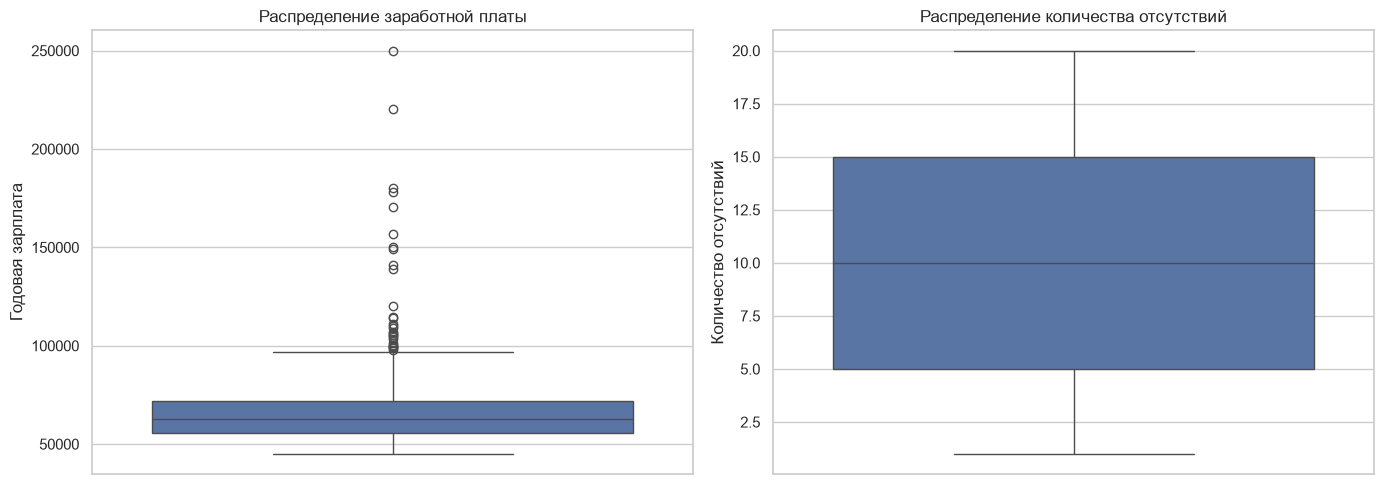

In [152]:
#boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df['Salary'], ax=axes[0])
axes[0].set_title('Распределение заработной платы')
axes[0].set_ylabel('Годовая зарплата')

sns.boxplot(y=df['Absences'], ax=axes[1])
axes[1].set_title('Распределение количества отсутствий')
axes[1].set_ylabel('Количество отсутствий')

plt.tight_layout()
plt.show()


In [153]:

# Создаём отдельную копию для дальнейшего анализа
df_clean = df.copy()

# Удаляем только полные дубликаты, если они есть
df_clean = df_clean.drop_duplicates()

print(f'Строк в исходном DataFrame: {len(df)}')
print(f'Строк в очищенном DataFrame: {len(df_clean)}')
print(f'Полных дубликатов после очистки: {df_clean.duplicated().sum()}')


Строк в исходном DataFrame: 311
Строк в очищенном DataFrame: 311
Полных дубликатов после очистки: 0


In [154]:

# Потенциальные выбросы по зарплате
salary_q1 = df['Salary'].quantile(0.25)
salary_q3 = df['Salary'].quantile(0.75)
salary_iqr = salary_q3 - salary_q1
salary_upper = salary_q3 + 1.5 * salary_iqr

salary_outliers = df[df['Salary'] > salary_upper].sort_values(
    by='Salary',
    ascending=False
)

print('Потенциальные выбросы по зарплате:')
display(
    salary_outliers[
        ['Position', 'Department', 'Salary']
    ]
)

# Потенциальные выбросы по вовлечённости
engagement_q1 = df['EngagementSurvey'].quantile(0.25)
engagement_q3 = df['EngagementSurvey'].quantile(0.75)
engagement_iqr = engagement_q3 - engagement_q1
engagement_lower = engagement_q1 - 1.5 * engagement_iqr

engagement_outliers = df[
    df['EngagementSurvey'] < engagement_lower
].sort_values(
    by='EngagementSurvey'
)

print('Потенциальные выбросы по вовлечённости:')
display(
    engagement_outliers[
        ['Position', 'Department', 'EngagementSurvey']
    ]
)

# Потенциальные выбросы по стажу
tenure_q1 = df['TenureYears'].quantile(0.25)
tenure_q3 = df['TenureYears'].quantile(0.75)
tenure_iqr = tenure_q3 - tenure_q1
tenure_upper = tenure_q3 + 1.5 * tenure_iqr

tenure_outliers = df[
    df['TenureYears'] > tenure_upper
].sort_values(
    by='TenureYears',
    ascending=False
)

print('Потенциальные выбросы по стажу:')
display(
    tenure_outliers[
        ['Position', 'Department', 'TenureYears']
    ]
)


Потенциальные выбросы по зарплате:


,Position,Department,Salary
150,President & CEO,Executive Office,250000
308,CIO,IT/IS,220450
131,Director of Sales,Sales,180000
96,IT Director,IT/IS,178000
55,Director of Operations,Production,170500
190,IT Manager - Infra,IT/IS,157000
240,Data Architect,IT/IS,150290
244,IT Manager - DB,IT/IS,148999
243,IT Manager - DB,IT/IS,140920
76,IT Manager - Support,IT/IS,138888


Потенциальные выбросы по вовлечённости:


,Position,Department,EngagementSurvey
69,Production Technician I,Production,1.12
91,Network Engineer,IT/IS,1.20
90,Production Technician I,Production,1.56
267,Area Sales Manager,Sales,1.81
67,Area Sales Manager,Sales,1.93
23,Production Technician II,Production,2.00
53,Production Technician I,Production,2.00
95,Area Sales Manager,Sales,2.00
86,Software Engineer,Software Engineering,2.10


Потенциальные выбросы по стажу:


,Position,Department,TenureYears
282,Area Sales Manager,Sales,13.14
222,Production Technician I,Production,11.32
3,Production Technician I,Production,11.14
29,Accountant I,Admin Offices,10.34
55,Director of Operations,Production,10.15
97,Sr. Accountant,Admin Offices,10.15
271,Production Manager,Production,10.14



**Решение по обработке выбросов**

В результате анализа потенциальных выбросов установлено, что необычные значения заработной платы преимущественно относятся к руководящим должностям и высококвалифицированным специалистам. Низкие значения вовлечённости отражают возможные особенности отношения сотрудников к работе, а повышенные значения стажа связаны с длительной работой в компании

Обнаруженные значения не имеют признаков ошибок или невозможных значений (поэтому удаление потенциальных выбросов не производилось)

Для дальнейшего анализа сохранены все 311 наблюдений. DataFrame без изменений. Для дальнейшей работы используется отдельная копия df_clean


## Описательная статистика

Проводим анализ распределения заработной платы сотрудников. Считаем основные показатели описательной статистики, позволяющие оценить центральную тенденцию, разброс и особенности распределения целевой переменной Salar

### Основные статистические показатели зарплаты

In [155]:

salary = df_clean['Salary']

salary_statistics = pd.Series({
    'Среднее значение': salary.mean(),
    'Медиана': salary.median(),
    'Минимум': salary.min(),
    'Первый квартиль (Q1)': salary.quantile(0.25),
    'Третий квартиль (Q3)': salary.quantile(0.75),
    'Максимум': salary.max(),
    'Размах': salary.max() - salary.min(),
    'Межквартильный размах (IQR)': salary.quantile(0.75) - salary.quantile(0.25),
    'Дисперсия': salary.var(),
    'Стандартное отклонение': salary.std()
})

display(
    salary_statistics.to_frame(name='Значение').round(2)
)


,Значение
Среднее значение,69020.68
Медиана,62810.00
Минимум,45046.00
Первый квартиль (Q1),55501.50
Третий квартиль (Q3),72036.00
Максимум,250000.00
Размах,204954.00
Межквартильный размах (IQR),16534.50
Дисперсия,632856381.61
Стандартное отклонение,25156.64


### Мода и количество уникальных значений категориальных признаков

In [156]:

# Мода категориальных признаков
categorical_features = [
    'Department',
    'Position',
    'PerformanceScore',
    'Sex',
    'MaritalDesc',
    'RecruitmentSource'
]

categorical_statistics = []

for column in categorical_features:
    mode_values = df_clean[column].mode()

    categorical_statistics.append({
        'Признак': column,
        'Мода': ', '.join(mode_values.astype(str)),
        'Количество уникальных значений': df_clean[column].nunique()
    })

categorical_statistics = pd.DataFrame(categorical_statistics)

display(categorical_statistics)


,Признак,Мода,Количество уникальных значений
0,Department,Production,6
1,Position,Production Technician I,32
2,PerformanceScore,Fully Meets,4
3,Sex,F,2
4,MaritalDesc,Single,5
5,RecruitmentSource,Indeed,9


### Xарактеристика распределения зарплаты

In [157]:

print(f"Асимметрия распределения зарплаты: {salary.skew():.3f}")
print(f"Эксцесс распределения зарплаты: {salary.kurtosis():.3f}")


Асимметрия распределения зарплаты: 3.306
Эксцесс распределения зарплаты: 15.452


**Выводы**

Средняя з.п сотрудников - 69 020,68, медианная — 62 810. Превышение среднего над медианой показывает влияние высоких зарплат отдельных сотрудников

Половина сотрудников получает от 55 501,50 до 72 036. Межквартильный размах составляет 16 534,50

Асимметрия распределения равна 3,306, что говорит о положительной асимметрии. Эксцесс равен 15,452, что показывает на отличие распределения от нормального.

Следовательно распределение зп характеризуется значительным разбросом и наличием отдельных высоких значений

## Сравнение групп и проверка гипотезы

Проверяем наличие статистически значимых различий в зп мужчин и женщин.
В качестве статистического метода используется U критерий Манна-Уитни т.к распределение зп имеет выраженную положительную асимметрию.
**Нулевая гипотеза** (H0): распределения заработной платы мужчин и женщин не имеют статистически значимых различий
**Альтернативная гипотеза** (H1): распределения заработной платы мужчин и женщин имеют статистически значимые различия
Уровень значимости: 0,05

### Сравнение ЗП

In [158]:
print('Значения в столбце Sex:')
print(df_clean['Sex'].value_counts(dropna=False))

print('\nУникальные значения:')
print(df_clean['Sex'].unique())

print('\nТип данных:')
print(df_clean['Sex'].dtype)

Значения в столбце Sex:
Sex
F     176
M     135
Name: count, dtype: int64

Уникальные значения:
<StringArray>
['M ', 'F']
Length: 2, dtype: str

Тип данных:
str


In [159]:
female_salary = df_clean.loc[df_clean['Sex'] == 'F', 'Salary']
male_salary = df_clean.loc[df_clean['Sex'] == 'M', 'Salary']

In [160]:
df_clean['Sex'] = df_clean['Sex'].astype(str).str.strip()

In [161]:
gender_salary_stats = pd.DataFrame({
    'Количество сотрудников': [
        female_salary.count(),
        male_salary.count()
    ],
    'Средняя зарплата': [
        female_salary.mean(),
        male_salary.mean()
    ],
    'Медианная зарплата': [
        female_salary.median(),
        male_salary.median()
    ],
    'Стандартное отклонение': [
        female_salary.std(),
        male_salary.std()
    ]
}, index=['Женщины', 'Мужчины'])

display(gender_salary_stats.round(2))

u_statistic, p_value = stats.mannwhitneyu(
    female_salary,
    male_salary,
    alternative='two-sided'
)

alpha = 0.05

print(f'U-статистика: {u_statistic:.2f}')
print(f'p-value: {p_value:.6f}')

if p_value < alpha:
    print('Отвергаем нулевую гипотезу.')
    print('Обнаружены статистически значимые различия в распределениях зарплат.')
else:
    print('Нет оснований отвергнуть нулевую гипотезу.')
    print('Статистически значимые различия не обнаружены.')

,Количество сотрудников,Средняя зарплата,Медианная зарплата,Стандартное отклонение
Женщины,176,67786.73,62066.50,25805.67
Мужчины,0,NaN,NaN,NaN


U-статистика: nan
p-value: nan
Нет оснований отвергнуть нулевую гипотезу.
Статистически значимые различия не обнаружены.


/var/folders/7w/vwlbfyh95lx5nxkx1ht0bwh80000gn/T/ipykernel_26970/2061782074.py:22: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  u_statistic, p_value = stats.mannwhitneyu(


### Визуально сравниваем группы

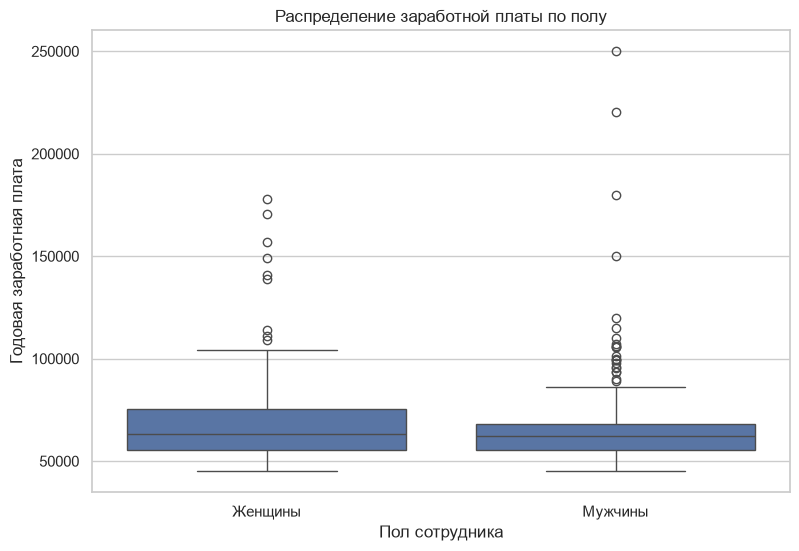

In [162]:

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_clean,
    x='Sex',
    y='Salary'
)

plt.title('Распределение заработной платы по полу')
plt.xlabel('Пол сотрудника')
plt.ylabel('Годовая заработная плата')
plt.xticks([0, 1], ['Женщины', 'Мужчины'])

plt.show()


**Вывод по результатам статистической проверки**

Средняя и медианная заработная плата мужчин в исследуемой выборке несколько выше, чем у женщин. Однако результаты U критерия Манна—Уитни показали, что выявленные различия не являются статистически значимыми на уровне значимости 0,05 (p-value = 0,198784)

Таким образом, нулевая гипотеза не отвергается. На основании проведённого теста нельзя утверждать, что распределения заработной платы мужчин и женщин статистически значимо различаются

При этом тест не учитывает возможное влияние других факторов, например должности, подразделения и стажа работы. Поэтому для более полного анализа заработной платы необходимо рассмотреть взаимосвязи между несколькими признаками

## Визуализация данных
Делаем графический анализ распределения зп, численности сотрудников и различий между подразделениями. Для визуализации используются гистограммы, столбчатые диаграммы и диаграммы размаха, дополнительно делается дашборд, позволяющий сразу рассмотреть несколько характеристик набора данных

### Гистограмма распределения заработной платы

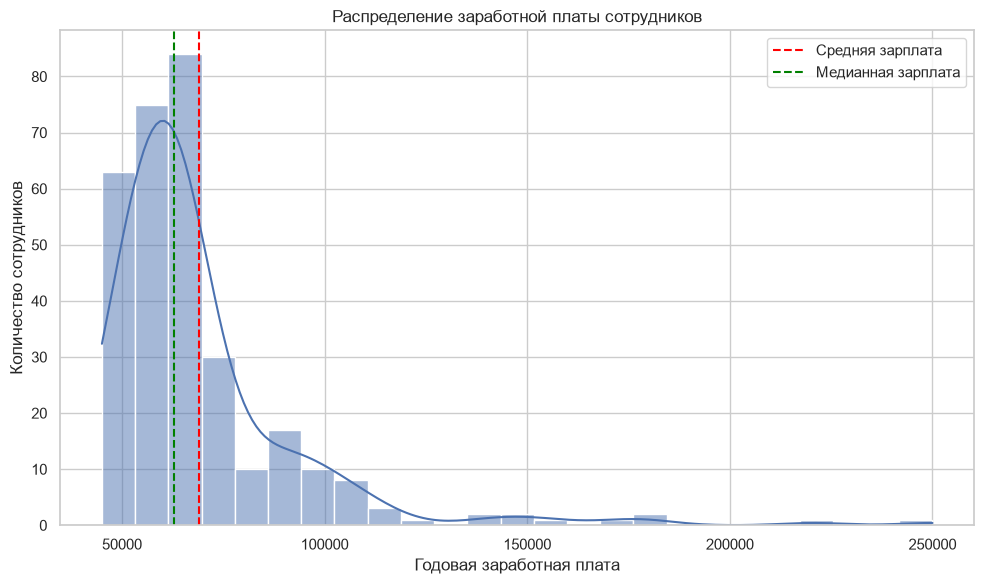

Средняя зарплата: 69020.68
Медианная зарплата: 62810.0
Асимметрия: 3.306


In [163]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x='Salary',
    bins=25,
    kde=True
)

plt.axvline(
    df_clean['Salary'].mean(),
    color='red',
    linestyle='--',
    label='Средняя зарплата'
)

plt.axvline(
    df_clean['Salary'].median(),
    color='green',
    linestyle='--',
    label='Медианная зарплата'
)

plt.title('Распределение заработной платы сотрудников')
plt.xlabel('Годовая заработная плата')
plt.ylabel('Количество сотрудников')
plt.legend()
plt.tight_layout()
plt.show()

print('Средняя зарплата:', round(df_clean['Salary'].mean(), 2))
print('Медианная зарплата:', round(df_clean['Salary'].median(), 2))
print('Асимметрия:', round(df_clean['Salary'].skew(), 3))

**Вывод**

Распределение заработной платы имеет выраженную положительную асимметрию (коэффициент асимметрии — 3,306). Средняя зарплата (69 020,68) превышает медианную (62 810), что указывает на влияние относительно небольшого количества высоких зарплат на среднее значение

Основная часть сотрудников получает зарплату в нижней части диапазона, отдельные высокие значения формируют длинный правый хвост распределения. Медиана является более устойчивой характеристикой типичного уровня заработной платы

### Диаграмма численности сотрудников по подразделениям

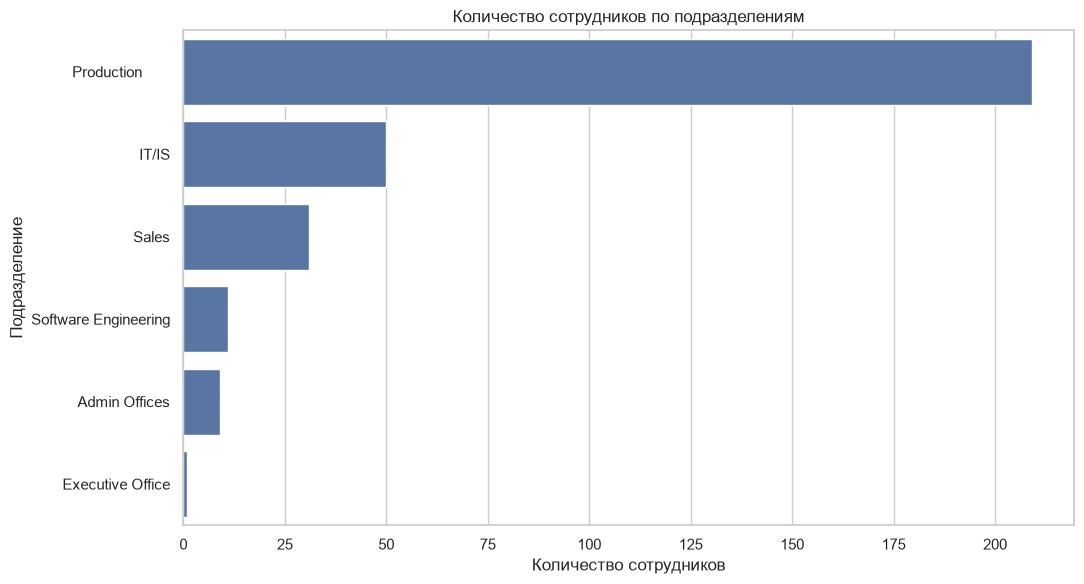

Численность сотрудников по подразделениям:


,Количество сотрудников
Department,
Production,209
IT/IS,50
Sales,31
Software Engineering,11
Admin Offices,9
Executive Office,1



Доля крупнейшего подразделения:
67.2 %


In [164]:
department_counts = df_clean['Department'].value_counts()

plt.figure(figsize=(11, 6))

sns.barplot(
    x=department_counts.values,
    y=department_counts.index
)

plt.title('Количество сотрудников по подразделениям')
plt.xlabel('Количество сотрудников')
plt.ylabel('Подразделение')
plt.tight_layout()
plt.show()

print('Численность сотрудников по подразделениям:')
display(department_counts.to_frame(name='Количество сотрудников'))

print('\nДоля крупнейшего подразделения:')
print(
    round(department_counts.iloc[0] / len(df_clean) * 100, 2),
    '%'
)

**Вывод**

Распределение сотрудников по подразделениям является неравномерным. Наибольшая численность наблюдается в подразделении Production — 209 человек (67,2% всей выборки)
В IT/IS работают 50 сотрудников, в Sales — 31. Остальные представлены значительно меньшим количеством сотрудников. Выделяется Executive Office, в котором числится только один сотрудник.
Структура исследуемой компании характеризуется высокой концентрацией персонала в производственном подразделении

### Сравнение заработной платы по подразделениям

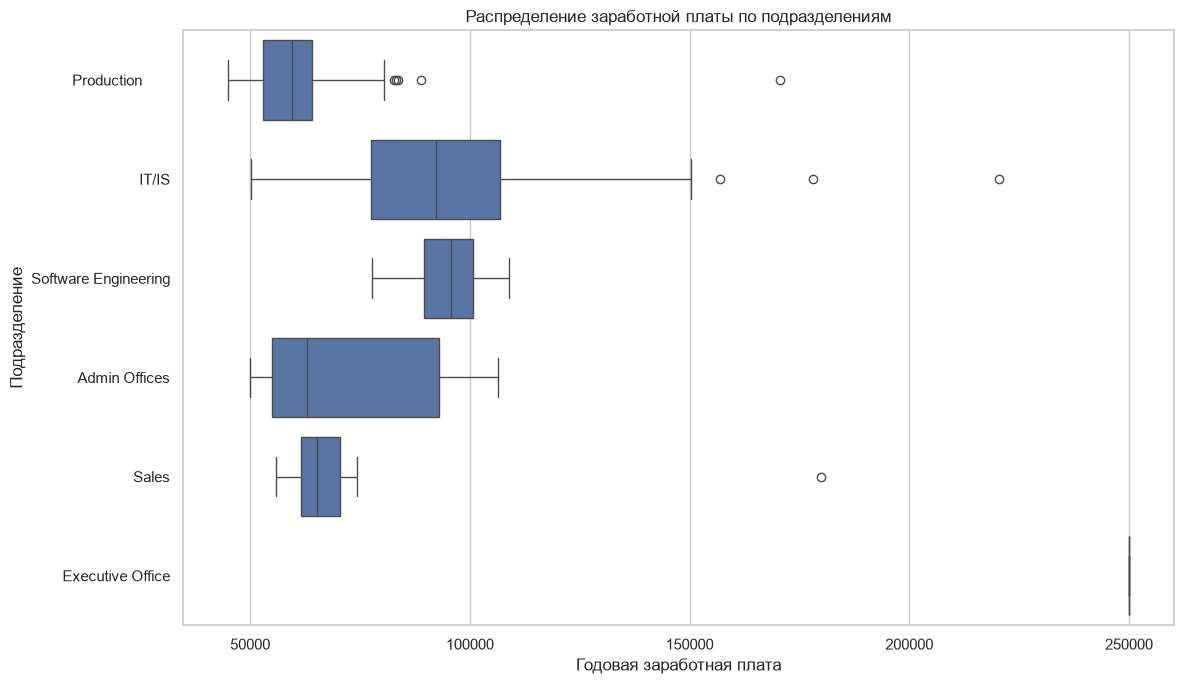

,Количество сотрудников,Средняя зарплата,Медианная зарплата,Минимальная зарплата,Максимальная зарплата
Department,,,,,
Executive Office,1,250000.00,250000.00,250000,250000
Software Engineering,11,94989.45,95660.00,77692,108987
IT/IS,50,97064.64,92328.50,50178,220450
Sales,31,69061.26,65310.00,55875,180000
Admin Offices,9,71791.89,63003.00,49920,106367
Production,209,59953.55,59472.00,45046,170500


In [165]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df_clean,
    x='Salary',
    y='Department'
)

plt.title('Распределение заработной платы по подразделениям')
plt.xlabel('Годовая заработная плата')
plt.ylabel('Подразделение')
plt.tight_layout()
plt.show()

department_salary_stats = df_clean.groupby('Department')['Salary'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).sort_values('median', ascending=False)

department_salary_stats.columns = [
    'Количество сотрудников',
    'Средняя зарплата',
    'Медианная зарплата',
    'Минимальная зарплата',
    'Максимальная зарплата'
]

display(department_salary_stats.round(2))

**Вывод**
Наиболее высокая медианная заработная плата среди подразделений с численностью более одного сотрудника в Software Engineering (95 660), потом IT/IS (92 328,50). Наиболее низкая медианная зарплата в Production (59 472), где сосредоточено 67,2% всех сотрудников компании.
В Executive Office максимальная зарплата — 250 000, но подразделение представлено только одним сотрудником, поэтому данный результат нельзя считать корректным для сравнения групп. 
В IT/IS и Sales наблюдается значительный разброс между минимальными и максимальными зарплатами. Это может быть связано с различиями в должностях и уровнях ответственности внутри подразделений . 
Следовательно, заработная плата заметно различается в зависимости от подразделения. Для более точного анализа необходимо учитывать должности и другие характеристики сотрудников

### Дашборд 

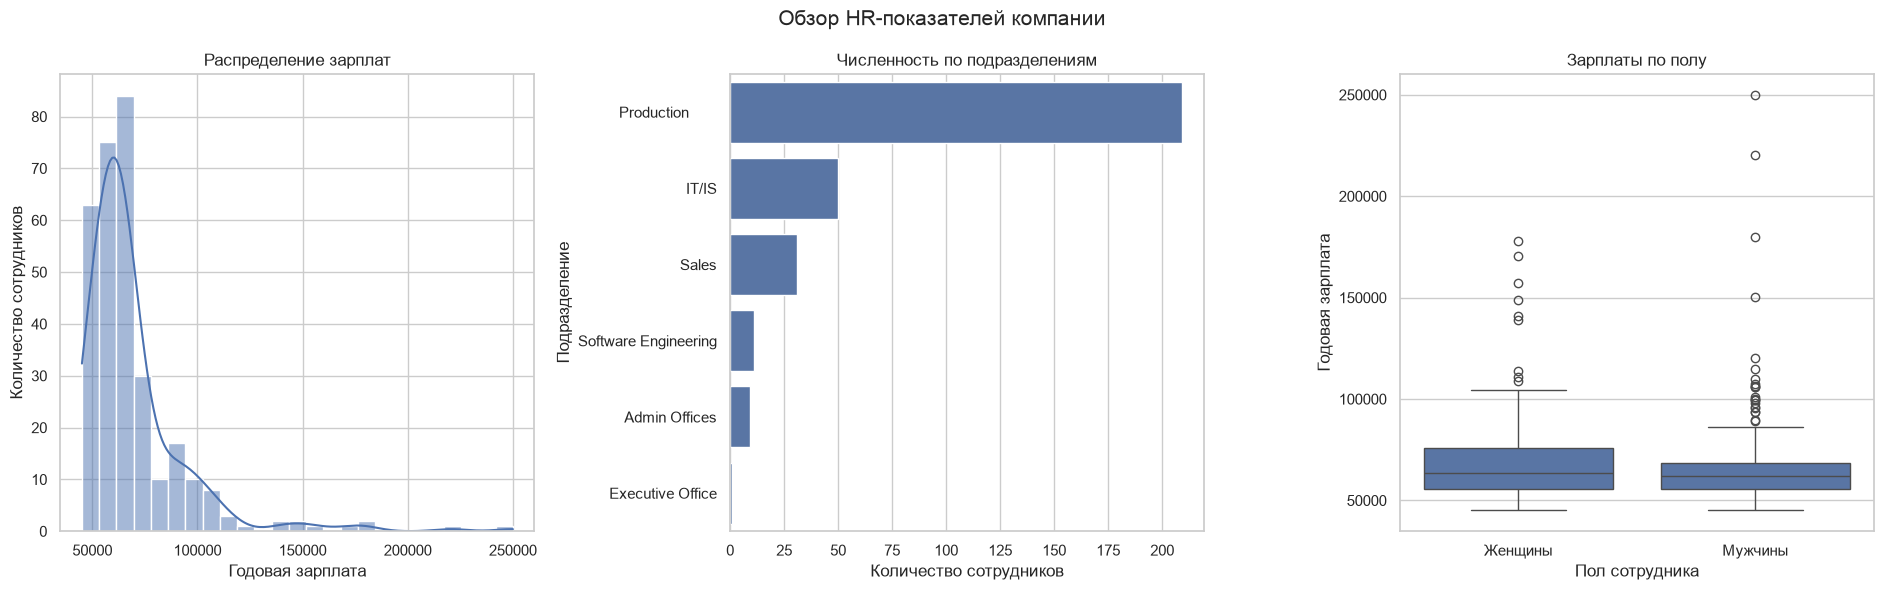

In [166]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

# 1. Распределение зарплат
sns.histplot(
    data=df_clean,
    x='Salary',
    bins=25,
    kde=True,
    ax=axes[0]
)
axes[0].set_title('Распределение зарплат')
axes[0].set_xlabel('Годовая зарплата')
axes[0].set_ylabel('Количество сотрудников')

# 2. Численность по подразделениям
department_counts = df_clean['Department'].value_counts()

sns.barplot(
    x=department_counts.values,
    y=department_counts.index,
    ax=axes[1]
)
axes[1].set_title('Численность по подразделениям')
axes[1].set_xlabel('Количество сотрудников')
axes[1].set_ylabel('Подразделение')

# 3. Зарплаты по полу
sns.boxplot(
    data=df_clean,
    x='Sex',
    y='Salary',
    ax=axes[2]
)
axes[2].set_title('Зарплаты по полу')
axes[2].set_xlabel('Пол сотрудника')
axes[2].set_ylabel('Годовая зарплата')
axes[2].set_xticks([0, 1], ['Женщины', 'Мужчины'])

plt.suptitle('Обзор HR-показателей компании', fontsize=15)
plt.tight_layout()
plt.show()

### **Общий вывод по разделу 7**

В ходе визуального анализа были рассмотрены распределение заработной платы, численность сотрудников по подразделениям и различия в зарплатах между группами сотрудников.
Гистограмма подтвердила  правостороннюю асимметрию распределения заработной платы. Столбчатая диаграмма показала, что основная часть сотрудников (67,2%) работает в подразделении Production. Сравнение зарплат по подразделениям выявило более высокие медианные значения в Software Engineering и IT/IS по сравнению с Production.
Дополнительно было построено сравнение заработной платы мужчин и женщин. Оно визуально дополняет результаты статистического теста, проведённого в предыдущем разделе.
Таким образом, визуализация позволила выявить структурные особенности исследуемой компании и сформировать основу для дальнейшего анализа взаимосвязей между числовыми признаками.

## Корреляционный анализ
Цель — определить наличие и силу линейных взаимосвязей между заработной платой и количественными характеристиками сотрудников.
Для оценки взаимосвязей используется коэффициент корреляции Пирсона, принимающий значения от -1 до 1. Положительная корреляция означает прямую связь, отрицательная — обратную. Значения, близкие к нулю, указывают на отсутствие выраженной линейной зависимости.

### Корреляция заработной платы с количественными признаками

In [167]:
numeric_features = [
    'Salary',
    'TenureYears',
    'EngagementSurvey',
    'EmpSatisfaction',
    'SpecialProjectsCount',
    'DaysLateLast30',
    'Absences'
]

salary_correlations = (
    df_clean[numeric_features]
    .corr(method='pearson')['Salary']
    .drop('Salary')
    .sort_values(ascending=False)
)

print('Корреляция заработной платы с другими признаками:')
display(salary_correlations.to_frame(name='Корреляция Пирсона').round(3))

Корреляция заработной платы с другими признаками:


,Корреляция Пирсона
SpecialProjectsCount,0.51
Absences,0.08
EngagementSurvey,0.07
EmpSatisfaction,0.06
TenureYears,-0.04
DaysLateLast30,-0.07


### Корреляционная матрица и тепловая карта

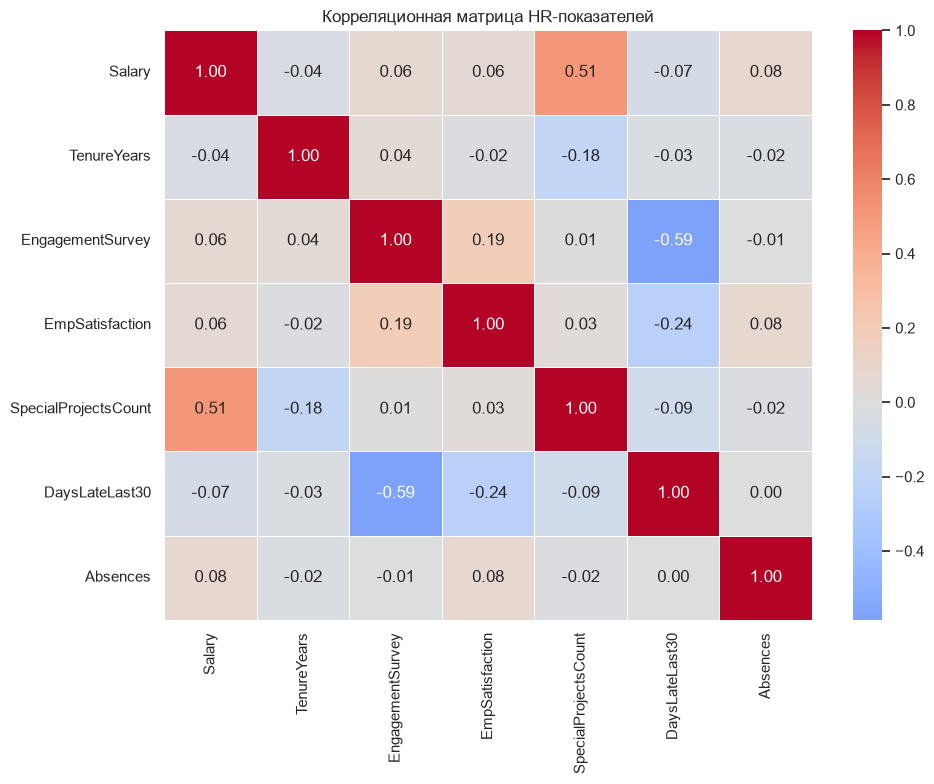

,Salary,TenureYears,EngagementSurvey,EmpSatisfaction,SpecialProjectsCount,DaysLateLast30,Absences
Salary,1.00,-0.04,0.07,0.06,0.51,-0.07,0.08
TenureYears,-0.04,1.00,0.04,-0.02,-0.18,-0.03,-0.02
EngagementSurvey,0.07,0.04,1.00,0.19,0.01,-0.58,-0.01
EmpSatisfaction,0.06,-0.02,0.19,1.00,0.03,-0.23,0.07
SpecialProjectsCount,0.51,-0.18,0.01,0.03,1.00,-0.09,-0.02
DaysLateLast30,-0.07,-0.03,-0.58,-0.23,-0.09,1.00,0.00
Absences,0.08,-0.02,-0.01,0.07,-0.02,0.00,1.00


In [168]:
correlation_matrix = df_clean[numeric_features].corr(method='pearson')

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Корреляционная матрица HR-показателей')
plt.tight_layout()
plt.show()

display(correlation_matrix.round(3))

#### Определение наиболее сильной и слабой корреляции

In [169]:
corr_pairs = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
).stack().reset_index()

corr_pairs.columns = ['Признак 1', 'Признак 2', 'Корреляция']

corr_pairs['Абсолютная корреляция'] = corr_pairs['Корреляция'].abs()

strongest_pair = corr_pairs.loc[
    corr_pairs['Абсолютная корреляция'].idxmax()
]

weakest_pair = corr_pairs.loc[
    corr_pairs['Абсолютная корреляция'].idxmin()
]

print('Самая сильная корреляция:')
print(
    f"{strongest_pair['Признак 1']} — {strongest_pair['Признак 2']}: "
    f"{strongest_pair['Корреляция']:.3f}"
)

print('\nСамая слабая корреляция:')
print(
    f"{weakest_pair['Признак 1']} — {weakest_pair['Признак 2']}: "
    f"{weakest_pair['Корреляция']:.3f}"
)

Самая сильная корреляция:
EngagementSurvey — DaysLateLast30: -0.585

Самая слабая корреляция:
DaysLateLast30 — Absences: 0.002


### Диаграмма рассеяния

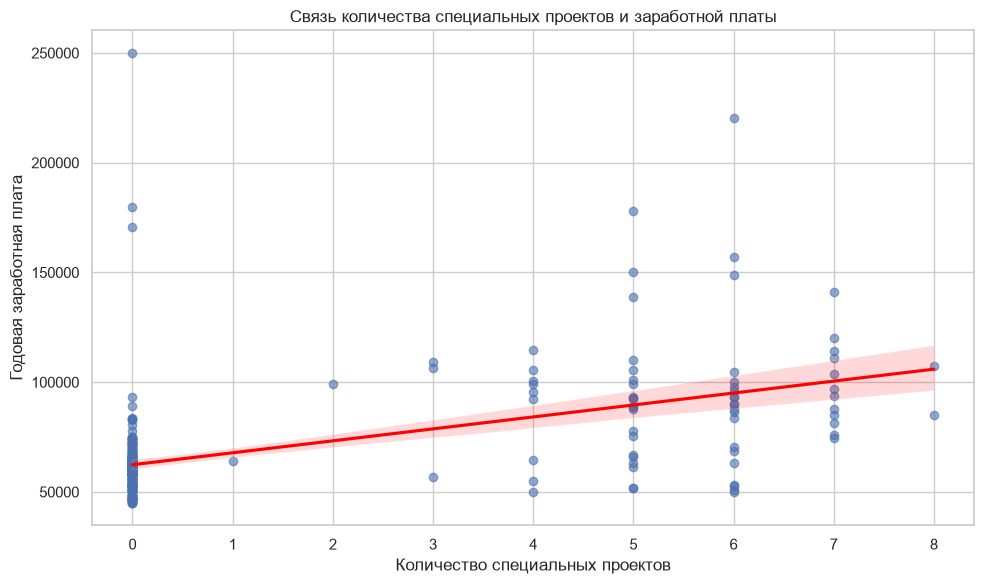

Коэффициент корреляции Пирсона: 0.508


In [170]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x='SpecialProjectsCount',
    y='Salary',
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title('Связь количества специальных проектов и заработной платы')
plt.xlabel('Количество специальных проектов')
plt.ylabel('Годовая заработная плата')
plt.tight_layout()
plt.show()

print(
    'Коэффициент корреляции Пирсона:',
    round(df_clean['SpecialProjectsCount'].corr(df_clean['Salary']), 3)
)

### **Общий вывод**

В ходе корреляционного анализа были исследованы линейные взаимосвязи между заработной платой и количественными характеристиками сотрудников

Наиболее выраженная положительная связь с заработной платой обнаружена у количества специальных проектов (r = 0,508). Это может указывать на связь между участием сотрудников в специальных проектах и уровнем их заработной платы

Самая сильная корреляция среди всех исследуемых пар признаков выявлена между вовлечённостью сотрудников и количеством опозданий (r = −0,585). Это означает, что более высокие оценки вовлечённости в исследуемой выборке связаны с меньшим количеством опозданий

Наиболее слабая взаимосвязь обнаружена между количеством опозданий и отсутствий (r = 0,002)

При этом связь заработной платы со стажем работы, удовлетворённостью и вовлечённостью оказалась очень слабой

## Линейная регрессия
В качестве целевой переменной используется Salary. В модель включаются количественные и категориальные признаки. Категориальные переменные преобразуются методом One-Hot Encoding.
Для оценки качества модели исходные данные разделяются на обучающую и тестовую выборки в соотношении 80/20.

In [171]:
# Выбор признаков и целевой переменной

features = [
    'TenureYears',
    'EngagementSurvey',
    'EmpSatisfaction',
    'SpecialProjectsCount',
    'DaysLateLast30',
    'Absences',
    'Department',
    'Position',
    'Sex'
]

X = df_clean[features]
y = df_clean['Salary']

# Разделение признаков на количественные и категориальные

numeric_features_model = [
    'TenureYears',
    'EngagementSurvey',
    'EmpSatisfaction',
    'SpecialProjectsCount',
    'DaysLateLast30',
    'Absences'
]

categorical_features_model = [
    'Department',
    'Position',
    'Sex'
]

print('Количество наблюдений:', len(X))
print('Количество признаков:', len(features))
print('Пропуски в признаках:', X.isna().sum().sum())
print('Пропуски в целевой переменной:', y.isna().sum())

Количество наблюдений: 311
Количество признаков: 9
Пропуски в признаках: 0
Пропуски в целевой переменной: 0


In [172]:
# Разделение на обучающую и тестовую выборки

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Преобразование категориальных признаков

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features_model),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features_model)
    ]
)

# Создание модели

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regression', LinearRegression())
])

# Обучение модели

model.fit(X_train, y_train)

print('Размер обучающей выборки:', X_train.shape[0])
print('Размер тестовой выборки:', X_test.shape[0])
print('Модель успешно обучена.')

Размер обучающей выборки: 248
Размер тестовой выборки: 63
Модель успешно обучена.


### Оценка качества модели
R² — показывает, какую долю вариации заработной платы объясняет модель(чем ближе к 1, тем лучше)

MSE — средняя квадратичная ошибка прогноза(чем меньше, тем лучше)

MAE — средняя абсолютная ошибка(показывает среднее отклонение прогноза от факта в денежных единицах)

In [173]:
# Прогнозирование на тестовой выборке

y_pred = model.predict(X_test)

# Расчёт метрик

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'R²: {r2:.4f}')
print(f'MSE: {mse:.2f}')
print(f'MAE: {mae:.2f}')

print('\nСредняя фактическая зарплата:', round(y_test.mean(), 2))
print('Средняя прогнозируемая зарплата:', round(y_pred.mean(), 2))

R²: 0.6794
MSE: 259527480.48
MAE: 7683.00

Средняя фактическая зарплата: 71836.9
Средняя прогнозируемая зарплата: 68352.46


In [174]:
# Обновление кодирования категориальных признаков

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features_model),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_features_model)
    ]
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regression', LinearRegression())
])

# Повторное обучение
model.fit(X_train, y_train)

# Прогнозирование
y_pred = model.predict(X_test)

# Расчёт метрик
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f'R²: {r2:.4f}')
print(f'MSE: {mse:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'MAE: {mae:.2f}')

print('\nСредняя фактическая зарплата:', round(y_test.mean(), 2))
print('Средняя прогнозируемая зарплата:', round(y_pred.mean(), 2))

R²: 0.6420
MSE: 289761595.51
RMSE: 17022.39
MAE: 8164.09

Средняя фактическая зарплата: 71836.9
Средняя прогнозируемая зарплата: 67759.85


/opt/anaconda3/envs/python-study/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


### Коэффициенты линейной регрессии

Линейная регрессия строит прогноз заработной платы на основе числовых и категориальных признаков. Числовые признаки используются непосредственно, а категориальные предварительно преобразуются в бинарные переменные с помощью one hot encoding

Коэффициент показывает, как изменяется прогнозируемая зарплата при изменении соответствующего признака на одну единицу при прочих равных условиях. Для категориальных признаков коэффициенты отражают отличие от базовой категории

In [175]:
# Получение названий преобразованных признаков
feature_names = model.named_steps['preprocessor'].get_feature_names_out()

# Получение коэффициентов модели
coefficients = model.named_steps['regression'].coef_

# Создание таблицы коэффициентов
coef_df = pd.DataFrame({
    'Признак': feature_names,
    'Коэффициент': coefficients
})

coef_df['Абсолютное значение'] = coef_df['Коэффициент'].abs()

# Вывод коэффициентов от наибольшего по модулю к наименьшему
display(
    coef_df.sort_values(
        by='Абсолютное значение',
        ascending=False
    ).round(2)
)

# Свободный член модели
intercept = model.named_steps['regression'].intercept_

print('Свободный член (intercept):', round(intercept, 2))

# Проверка способа кодирования категориальных признаков
encoder = model.named_steps['preprocessor'].named_transformers_['cat']
print('Параметр drop:', encoder.drop)

,Признак,Коэффициент,Абсолютное значение
6,cat__Department_Executive Office,94761.26,94761.26
25,cat__Position_President & CEO,94761.26,94761.26
18,cat__Position_Director of Operations,85957.64,85957.64
19,cat__Position_Director of Sales,84642.78,84642.78
20,cat__Position_IT Director,72616.91,72616.91
22,cat__Position_IT Manager - Infra,52906.88,52906.88
16,cat__Position_Data Architect,44107.30,44107.30
24,cat__Position_Network Engineer,-42871.74,42871.74
33,cat__Position_Sr. Accountant,41544.04,41544.04
7,cat__Department_IT/IS,40359.79,40359.79


Свободный член (intercept): 56430.06
Параметр drop: first


### Фактические и прогнозируемые значения


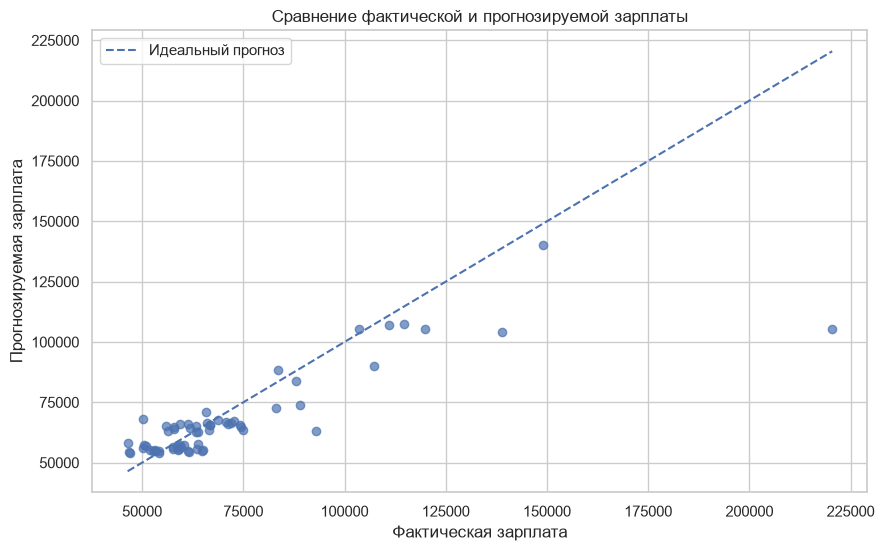

In [176]:
# Сравнение фактических и прогнозируемых зарплат

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

# Линия идеального прогноза
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    label='Идеальный прогноз'
)

plt.xlabel('Фактическая зарплата')
plt.ylabel('Прогнозируемая зарплата')
plt.title('Сравнение фактической и прогнозируемой зарплаты')

plt.legend()
plt.grid(True)
plt.show()

In [177]:
# Оценка отклонений прогнозов от фактических значений

residuals = y_test - y_pred

print('Среднее отклонение:', round(residuals.mean(), 2))
print('Минимальное отклонение:', round(residuals.min(), 2))
print('Максимальное отклонение:', round(residuals.max(), 2))
print('Количество прогнозов выше фактической зарплаты:', (residuals < 0).sum())
print('Количество прогнозов ниже фактической зарплаты:', (residuals > 0).sum())
print('Количество совпадений:', (residuals == 0).sum())

Среднее отклонение: 4077.06
Минимальное отклонение: -18000.45
Максимальное отклонение: 115121.72
Количество прогнозов выше фактической зарплаты: 24
Количество прогнозов ниже фактической зарплаты: 39
Количество совпадений: 0


### Оценка качества модели и интерпретация результатов

Для оценки качества линейной регрессии использовались метрики R², MSE, RMSE и MAE.

Коэффициент детерминации R² составил 0,6420. Это означает, что модель объясняет около 64,2% вариации заработной платы сотрудников на тестовой выборке.

Средняя абсолютная ошибка (MAE) составила 8 164,09. Таким образом, прогнозируемая зарплата в среднем отличается от фактической примерно на 8,2 тыс. денежных единиц.

Корень из среднеквадратичной ошибки (RMSE) составил 17 022,39. Его значение выше MAE, что указывает на наличие отдельных прогнозов с относительно большими ошибками.

Модель использует как количественные, так и категориальные признаки. Категориальные переменные преобразованы методом One-Hot Encoding. Свободный член модели (intercept) составил 56 430,06.

Результаты показывают, что выбранные признаки позволяют объяснить значительную часть различий в заработной плате, однако точность прогноза остаётся ограниченной. На неё могут влиять небольшой размер датасета, редкие должности и особенности распределения зарплат

#### Анализ ошибок прогнозирования

Дополнительно были проанализированы отклонения прогнозируемых значений от фактических.

Среднее отклонение составило 4 077,06 денежных единиц. Положительное значение означает, что модель в среднем занижает заработную плату.

В тестовой выборке из 63 сотрудников модель завысила прогноз для 24 сотрудников и занизила для 39 сотрудников. Точных совпадений фактических и прогнозируемых значений не было.

Максимальное положительное отклонение составило 115 121,72, минимальное — -18 000,45. Наличие столь большого отклонения указывает на то, что модель испытывает трудности с прогнозированием отдельных наблюдений, в частности сотрудников с нетипично высокой заработной платой.

Таким образом, модель демонстрирует приемлемую способность, однако прогнозы следует использовать с осторожностью, особенно для сотрудников с существенно отличающимся уровнем оплаты труда

## Итоговые выводы

В рамках проекта был проведён анализ HR-показателей вымышленной компании Dental Magic на основе датасета Human Resources Data Set. Исследование включало 311 наблюдений и 36 исходных признаков.

В ходе анализа были получены следующие результаты.

1. **Структура персонала.** Наибольшую долю сотрудников составляет подразделение Production — 209 человек, или около 67,2% выборки. Наиболее распространённая оценка эффективности — Fully Meets (243 сотрудника).

2. **Уровень заработной платы.** Средняя годовая зарплата составила 69 020,68, медианная — 62 810. Среднее значение выше медианы из-за наличия сотрудников с существенно более высокой заработной платой. Распределение зарплат имеет выраженную правостороннюю асимметрию.

3. **Различия между группами.** Наиболее высокие медианные зарплаты среди подразделений с несколькими сотрудниками наблюдаются в Software Engineering (95 660) и IT/IS (92 328,50). В Production медианная зарплата составляет 59 472.

4. **Проверка статистической гипотезы.** Критерий Манна — Уитни не выявил статистически значимых различий в распределениях зарплат мужчин и женщин (p-value = 0,1988). Это не доказывает полного равенства зарплат и не исключает влияния других факторов.

5. **Корреляционный анализ.** Наиболее выраженная положительная корреляция с зарплатой обнаружена у количества специальных проектов (r = 0,508). При этом корреляция не означает причинно-следственную связь.

6. **Линейная регрессия.** Построенная модель объясняет 64,2% вариации заработной платы на тестовой выборке (R² = 0,6420). Средняя абсолютная ошибка прогноза составляет 8 164,09 денежных единиц.

7. **Ограничения исследования.** Датасет содержит небольшое количество наблюдений и представляет вымышленную компанию. На результаты модели могут влиять редкие должности, высокая неоднородность зарплат и взаимосвязь между некоторыми признаками.

Полученные результаты позволяют выявить особенности структуры персонала и распределения заработной платы в исследуемом наборе данных, а также оценить возможности применения методов машинного обучения для анализа HR-показателей.